# MQT SCPD 4-qubit benchmark: a Quantcore-PDK rebuild, step by step

**Source:** Feldmeier, Walter, Huber, Bhattacharjee, Filipp, Wille, *Physical Design Automation for Planar
Superconducting Quantum Chips* (TCAD, under review). Supplementary data
<https://github.com/cda-tum/planar-superconducting-pd>, licence **MIT** (© 2026 The Munich Quantum Toolkit); the
layout tool is [MQT SCPD](https://github.com/munich-quantum-toolkit/scpd). Read on 2026-11-19, as data only (none of
the tool's code is used or copied): `inputs/4q/config.toml`, `inputs/4q/routing_config.json` (port positions and
obstacle polygons), `layouts/unrouted/gds/4q_unrouted.gds` and `layouts/routed/gds/4q_routed.gds` (read with
KLayout's Python module) and `qor/qor.csv`. Spec: `docs/designs/community/planar_superconducting_pd.md`.

**What the chip is.** The smallest of the eight benchmark chips that MQT SCPD places and routes: four qubits on a
2 × 2 grid, a tunable coupler on each edge of the square, 16 launchers (four per side on a 1600 µm pitch), one
feedline carrying four λ/4 readouts of d_fix = 2500 µm, eight control wires (four qubit drives, four coupler flux
lines) and five airbridges where a control wire crosses the feedline. The benchmark holds no device geometry:
qubits, couplers and launchers are abstract blocks (routing obstacles) with named ports, and the routed GDS adds the
wire footprints. The other seven chips (9 to 69 qubits) use the same three block types; the recipe below builds any
of them once their block centres are read from `layouts/unrouted/gds/<n>q_unrouted.gds`.

**This notebook rebuilds the 4-qubit chip in the Quantcore PDK; it is not a replica.** Each block becomes a library
component at the block's position and orientation, and each connection of the routed benchmark becomes a qcc route:

| topic | source (MQT SCPD, 4Q) | this rebuild |
|---|---|---|
| die and frame | launcher array 6.9 × 6.5 mm, no frame | PDK 7.5 × 7.5 mm die with its frame and the device ID `SCPD-4Q`; the launcher array is centred on it (Designer = source + (−101.54, +2176.71) µm) |
| stack | none | PDK sapphire 650 µm, εr 10.25 |
| qubits | four 680 × 680 µm blocks, each with a readout port and a drive stub | Quantcore `Xmon` (620 µm tip to tip) at each block centre, PDK trilayer junction |
| couplers | four 814 × 1420 µm blocks with a flux port and a bridge pair | `metal:TunableCoupler01` with a 1400 µm island on the qubit–qubit axis, PDK trilayer SQUID |
| launchers | 16 blocks of 500 × 500 µm | Quantcore `BondPad` with the same 500 × 500 µm etch, moved to the **PDK pad rule** (outer etch 100 µm from the die edge) |
| readouts | λ/4 of 2500 ± 100 µm ending in a 200 × 182 µm coupler footprint on the feedline | λ/4 hangers of 2425 / 2475 / 2525 / 2575 µm plus a 200 µm coupled section, at the source's coupler positions |
| routing | the routed GDS: one feedline in five segments, eight wires, 45° corners | qcc routes on the routed GDS's corner points, meanders for the resonator lengths |
| bridges | five, on the wires that cross the feedline | a KQC airbridge at each of the five crossings |
| cheese | none | PDK band (`cheese: "auto"`) |
| netlist, LOM, FEM jobs | none | ours |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far: the die, the 16 launchers, the feedline, the four Xmons with their trilayer
junctions, their λ/4 hanger readouts, the four tunable couplers with the declared couplings, the drive and flux
lines with their airbridges, and then the whole chip (sim groups, centring, save). Then the same steps as the Flow
strip of the Quantcore KLayout plugin: **Check** (DRC, netlist), **LOM** (simulation and plots), **Simulate** (export
to HFSS, the component simulation, the eigenmode simulation, the full-wave run), **Results** (plots, the values, FEM
against the LOM, a feedback step and the iteration to a target) and **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook saves
`scpd_4q.json`.

## Setup

The notebook runs from the repository root. `_common` holds the table, snapshot, coupling and PDK helpers shared by
the design notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with
`QCC_LIVE=0` (tests, batch runs) the snapshots are rendered headless.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj
from quantcore_circuits.lom import estimates as est
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)
EPS = est.substrate_eps(get_pdk())               # sapphire, εr 10.25

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. The library applies every one of them: the frame and the cheese in the chip
build, the pad rule through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## The benchmark data

`config.toml` sorts the ports into kinds and sets the design rules; `routing_config.json` gives every port's position
and direction and every block's outline; the routed GDS shows the wires MQT SCPD drew. All positions below are in the
source frame (µm) and go through `P(x, y)` into the Designer frame.

| kind (config.toml) | ports | what MQT SCPD routes |
|---|---|---|
| `resonator` | `Q1.port0` … `Q4.port0` | a λ/4 of d_fix = 2500 ± 100 µm to a coupler footprint on a feedline |
| `conventional` | `Q1.port1` … `Q4.port1` (drive), `C12.port0` … `C14.port0` (flux) | one wire to a launcher each |
| `bridge_pair` | `C12.port1` / `C12.port2` … | the two ends of a coupler a wire may cross |
| `launcher` | `Chip.port0` … `Chip.port15` | feedline ends and control-wire ends |

Design rules of the benchmark: wire spacing 185 µm, obstacle spacing 25 µm, bend radius ≥ 50 µm, straight ≥ 100 µm,
at most four resonators per feedline, no feedline terminations. The routed 4Q chip (`4q_routed.gds`, MQT SCPD's
result) uses one feedline from `Chip.port0` to `Chip.port10` and these wires:

| wire | from | to | crosses the feedline |
|---|---|---|---|
| Q1 drive | `Q1.port1` (north) | `Chip.port14` | no |
| Q2 drive | `Q2.port1` (north) | `Chip.port12` | no |
| Q3 drive | `Q3.port1` (south) | `Chip.port6` | yes (bridge) |
| Q4 drive | `Q4.port1` (west) | `Chip.port2` | yes (bridge) |
| C12 flux | `C12.port0` (north) | `Chip.port13` | no |
| C23 flux | `C23.port0` (east) | `Chip.port9` | yes (bridge) |
| C34 flux | `C34.port0` (south) | `Chip.port5` | yes (bridge) |
| C14 flux | `C14.port0` (west) | `Chip.port1` | yes (bridge) |

`Chip.port3`, `port4`, `port7`, `port8`, `port11` and `port15` stay unused. The benchmark's figures (`qor.csv`): 17
point-to-point connections, 10.32 mm of control wire, 80 bends of 45°, 5 bridges.

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so
the feedline is drawn as soon as its two launchers exist (segment 3), each readout once its qubit is there (segment 5)
and the control lines once their ends are (segment 7). Every position is a source coordinate mapped by `P`, so the
order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the PDK's 7.5 mm die with its frame |
| 2 | the 16 launchers (Quantcore `BondPad`s with the source's footprint) on the PDK pad rule |
| 3 | the readout line: the feedline from `L0` to `L10` on the routed benchmark's corners |
| 4 | the four Xmons with their trilayer junctions |
| 5 | the four λ/4 hanger readouts |
| 6 | the coupling: four `TunableCoupler01`s with trilayer SQUIDs and the declared capacitances |
| 7 | the control routing: four drive ends and lines, four flux lines, five airbridges |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip on the PDK's standard 7.5 mm die. The build draws the frame round it: L
dicing markers (1000/0), 3 × 3 alignment grids (1001/0) in the corners, the chip boundary (100/0) and the device ID
`SCPD-4Q` on a free edge.

The source's launcher array spans x 401.5…7301.5 µm and y −1676.7…4823.3 µm. `P(x, y)` shifts it by
(−101.54, +2176.71) µm so that the array is centred on the die; every block keeps its place relative to the others.

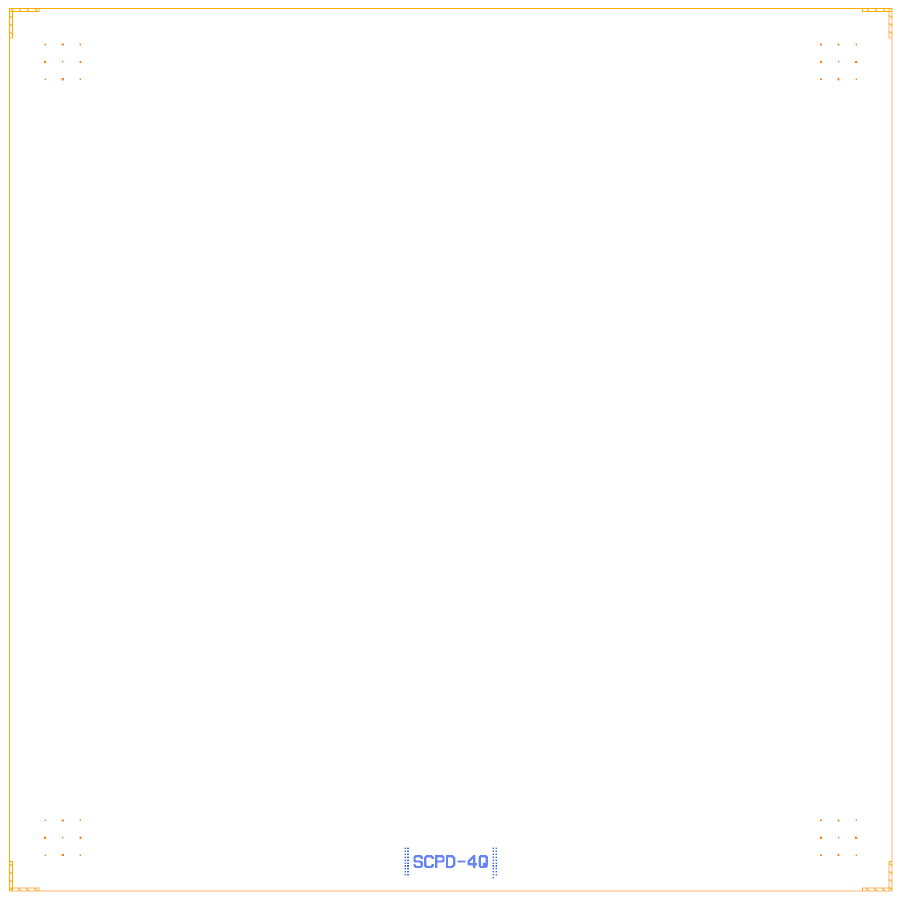

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/scpd_4q_die.png')

In [5]:
W = H = 7500                                     # PDK standard die
DX, DY = -101.54, 2176.71                        # source µm → Designer µm: the launcher array centred on the die
P = lambda x, y: (round(x + DX, 2), round(y + DY, 2))
PP = lambda pts: [P(x, y) for x, y in pts]
d = Designer("scpd_4q", box=(0, 0, W, H), chip={"name_chip": "SCPD-4Q"}, live=LIVE)
layout_step(d, OUT / "scpd_4q_die.png", size=(900, 900), width=320)

## Design 2 · Bond pads: the 16 launchers on the PDK pad rule

Each source launcher is a 500 × 500 µm block: a 300 µm deep pad area and a 200 µm taper to the 22 µm wide CPW
(10 µm centre, 6 µm gaps). The rebuild draws Quantcore `BondPad`s with the same footprint: a 300 × 200 µm pad, a 100 µm
gap round it and a 200 µm taper. `L<k>` stands for the source's `Chip.port<k>`. The PDK puts every launcher with
the outer edge of its etch **`frame.pad_edge` = 100 µm from the die edge**: `edge="w"` / `"s"` / `"e"` / `"n"` slides
each pad perpendicular to that edge until it holds, keeping its position along the edge. Here that moves the west
and east launchers 200 µm outward and the north and south ones 400 µm; the lines to them get that much longer.
`pads_md(d)` lists the distances.

Six launchers (`L3`, `L4`, `L7`, `L8`, `L11`, `L15`) stay unused, as in the routed benchmark.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| L0 | `BondPad` | w | 100.0 | ✓ |
| L1 | `BondPad` | w | 100.0 | ✓ |
| L2 | `BondPad` | w | 100.0 | ✓ |
| L3 | `BondPad` | w | 100.0 | ✓ |
| L4 | `BondPad` | s | 100.0 | ✓ |
| L5 | `BondPad` | s | 100.0 | ✓ |
| L6 | `BondPad` | s | 100.0 | ✓ |
| L7 | `BondPad` | s | 100.0 | ✓ |
| L8 | `BondPad` | e | 100.0 | ✓ |
| L9 | `BondPad` | e | 100.0 | ✓ |
| L10 | `BondPad` | e | 100.0 | ✓ |
| L11 | `BondPad` | e | 100.0 | ✓ |
| L12 | `BondPad` | n | 100.0 | ✓ |
| L13 | `BondPad` | n | 100.0 | ✓ |
| L14 | `BondPad` | n | 100.0 | ✓ |
| L15 | `BondPad` | n | 100.0 | ✓ |

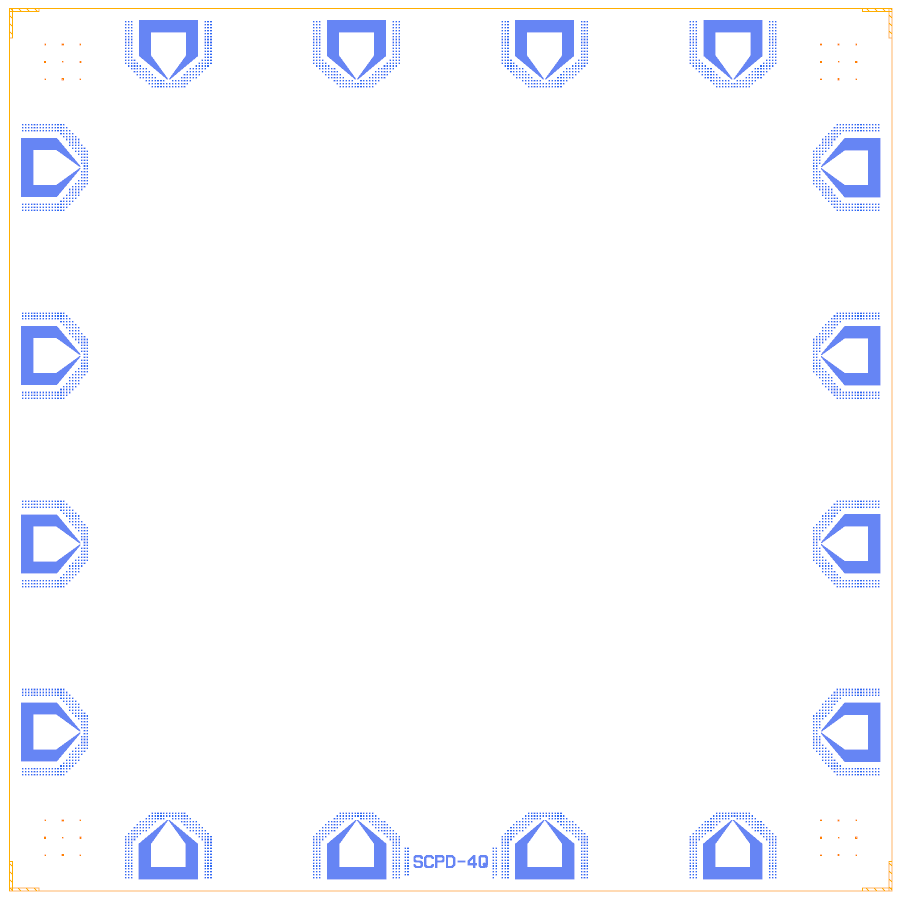

**On the chip so far:** 16 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 16 component(s) `L0`, `L1`, `L2`, `L3`, `L4`, `L5`, `L6`, `L7` … (+8).

WindowsPath('examples/designs/community/scpd_4q_s2_pads.png')

In [6]:
PAD = dict(pad_width=300, pad_height=200, pad_gap=100, taper_length=200)   # 500 × 500 µm etch, the source's block
LAUNCHERS = {  # Chip.port<k>: taper tip (source µm), rotation (port a facing the chip), die edge
    0: (901.54, 3973.29, -90, "w"), 1: (901.54, 2373.29, -90, "w"), 2: (901.54, 773.29, -90, "w"),
    3: (901.54, -826.71, -90, "w"), 4: (1451.54, -1176.71, 0, "s"), 5: (3051.54, -1176.71, 0, "s"),
    6: (4651.54, -1176.71, 0, "s"), 7: (6251.54, -1176.71, 0, "s"), 8: (6801.54, -826.71, 90, "e"),
    9: (6801.54, 773.29, 90, "e"), 10: (6801.54, 2373.29, 90, "e"), 11: (6801.54, 3973.29, 90, "e"),
    12: (6251.54, 4323.29, 180, "n"), 13: (4651.54, 4323.29, 180, "n"), 14: (3051.54, 4323.29, 180, "n"),
    15: (1451.54, 4323.29, 180, "n")}
L = {}
with d.batch():
    for k, (x, y, r, e) in LAUNCHERS.items():
        L[k] = d.add(f"L{k}", "BondPad", at=P(x, y), rot=r, edge=e, **PAD)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "scpd_4q_s2_pads.png", size=(900, 900), width=320)

## Design 3 · Readout: the feedline

The routed benchmark draws one feedline from `Chip.port0` (west, top) down the west side, along the south side and up
the east side to `Chip.port10`, with 45° corners in the south-west and south-east. The rebuild routes it through the
same corner points (read off the routed GDS's wire footprint; the source's 91 µm jog just after `Chip.port0` is left
out): a 10 / 6 µm CPW with the PDK bend radius. It needs no qubit, so it comes first; all four readouts hang on it.

FL: 13744.3 µm


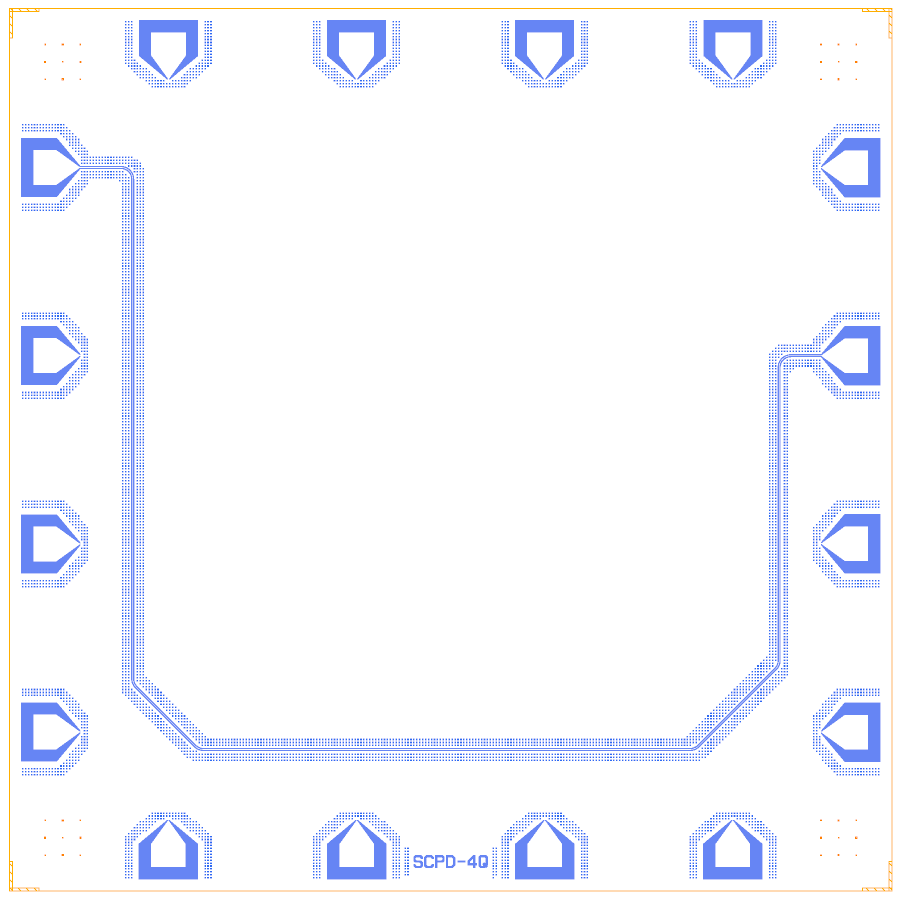

**On the chip so far:** 16 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('examples/designs/community/scpd_4q_s3_feedline.png')

In [7]:
FL_CORNERS = [(1148.8, 3973.29), (1148.8, -414.2), (1708.5, -973.9), (5928.0, -973.9), (6643.6, -258.3),
              (6643.6, 2373.29)]                 # source µm: west side x 1148.8, south side y −973.9, east side x 6643.6
fl = d.route("FL", L[0].a, L[10].a, nodes=PP(FL_CORNERS))
rebuild(d)
print(f"FL: {fl.length:.1f} µm")
layout_step(d, OUT / "scpd_4q_s3_feedline.png", size=(900, 900), width=320)

## Design 4 · Qubit placement: four Xmons with trilayer junctions

**The junction.** The source gives no qubit parameters. The qubits have one drive wire each and no flux line, so they
are fixed-frequency transmons: `trilayer_junction("Xmon")` returns the PDK nominal Nb/AlOx/Nb trilayer junction
(R_n 45 kΩ, inside the 40–50 kΩ window) and the values the LOM uses.

**The qubits.** A qubit block is a 680 × 680 µm square with a 96 µm readout tab on one side and a drive stub 80 µm off
another. Each Quantcore `Xmon` sits at its square's centre with 620 µm tip to tip (25 µm arms, 25 µm gap), so the
cross fills the square. Its arms point at the four neighbours of the block: the readout tab, the drive stub and the two
couplers. The Xmon draws its junction under the south arm and its claws on the other three, so each one is rotated
until the junction arm faces the drive stub and the claw (`claw_n`, `claw_w` or `claw_e` in the cell's own frame)
faces the readout tab:

| qubit | readout | drive | couplers | rotation | claw |
|---|---|---|---|---|---|
| Q1 (north-west) | west | north | C12 east, C14 south | 180° | `claw_e` |
| Q2 (north-east) | east | north | C12 west, C23 south | 180° | `claw_w` |
| Q3 (south-east) | east | south | C23 north, C34 west | 0° | `claw_e` |
| Q4 (south-west) | south | west | C14 north, C34 east | −90° | `claw_e` |

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0} → R_n 45.0 kΩ (PDK window 40–50 kΩ)
<Xmon Q1 ports=['claw_e']>


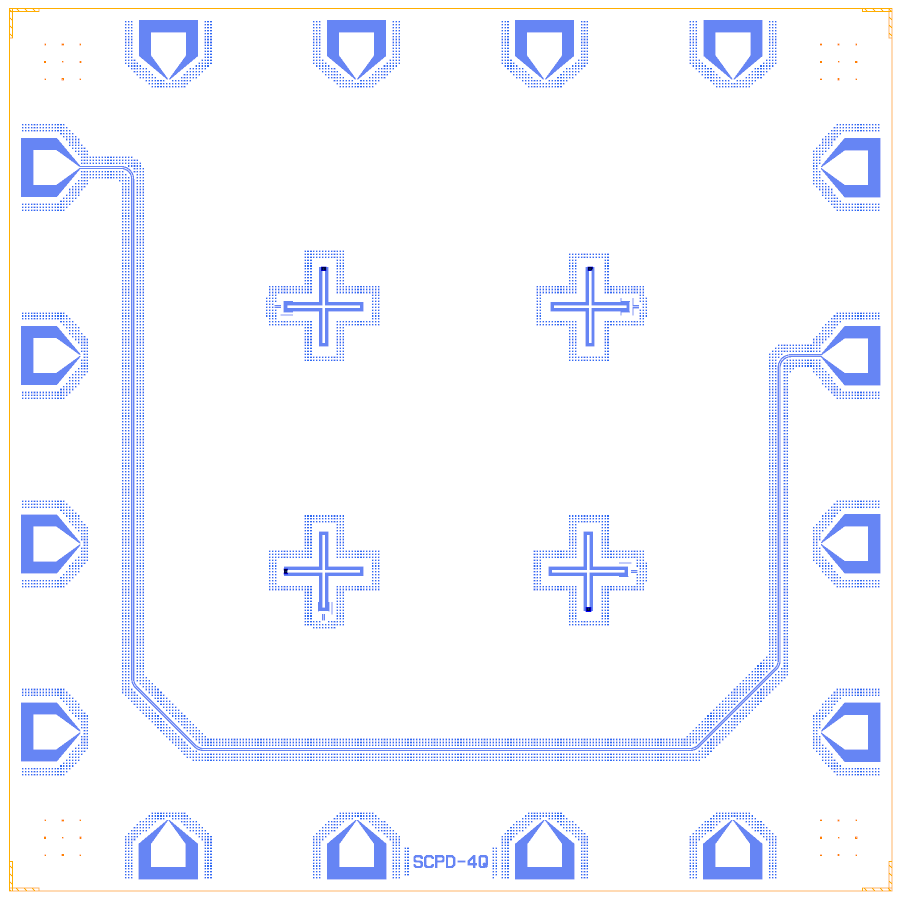

**On the chip so far:** 16 pads · 4 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 4 component(s) `Q1`, `Q2`, `Q3`, `Q4`.

WindowsPath('examples/designs/community/scpd_4q_s4_qubits.png')

In [8]:
JJP, JJ = trilayer_junction("Xmon")              # PDK nominal junction (R_n 45 kΩ)
print("junction:", JJP, JJ, f"→ R_n {rn_from_lj(JJ['Lj_nH']) / 1e3:.1f} kΩ (PDK window 40–50 kΩ)")
QXY = {"Q1": (2772.2, 2790.1), "Q2": (5036.3, 2789.2), "Q3": (5022.2, 540.1), "Q4": (2772.2, 540.1)}  # square centres
QROT = {"Q1": (180, "e"), "Q2": (180, "w"), "Q3": (0, "e"), "Q4": (-90, "e")}   # rotation, readout claw
XMON = dict(cross_length=620, arm_width=25, gap=25)
q = {}
with d.batch():
    for n, (x, y) in QXY.items():
        r, claw = QROT[n]
        q[n] = d.add(n, "Xmon", at=P(x, y), rot=r, claws=[claw], junction=JJ, **XMON, **JJP)
print(q["Q1"])
layout_step(d, OUT / "scpd_4q_s4_qubits.png", size=(900, 900), width=320)

## Design 5 · Readout: four λ/4 hangers on the feedline

Each resonator runs from its qubit's claw (open end) to a **hanger** on the feedline: a 200 µm section beside the
line, on the chip's inner side, shorted at its end. `fl.hanger(near=(x, y), ...)` centres it at the feedline point
nearest the source's 200 × 182 µm coupler footprint, so R1 hangs on the west side, R2 on the east side, R4 on the
south side and R3 on the 45° segment in the south-east. `direction` sets which end the resonator enters, as in the
routed GDS.

**Lengths.** The benchmark asks for 2500 ± 100 µm of resonator wire (`target_resonator_length`,
`resonator_length_tolerance`) and gives every resonator the same length. Four readouts on one feedline need four
frequencies, so the rebuild staggers the wire inside that tolerance: 2425, 2475, 2525 and 2575 µm, each plus the
200 µm coupled section (`meander=` is the whole λ/4). The router draws the length the waypoint path leaves over as one
KQC `Meander`.

**Waypoints.** Each path is two corners from the claw towards its coupler. The last one lies on the coupler's
approach line, the line the route must follow into the coupler's bend: for the west, south and east couplers an axis
line through the coupler's end, for R3 the 45° line x + y = 6112.0 (source µm), which is perpendicular to the
diagonal feedline.

{'FL': 13744.3, 'R1': 2625.0, 'R2': 2675.0, 'R3': 2725.0, 'R4': 2775.0}


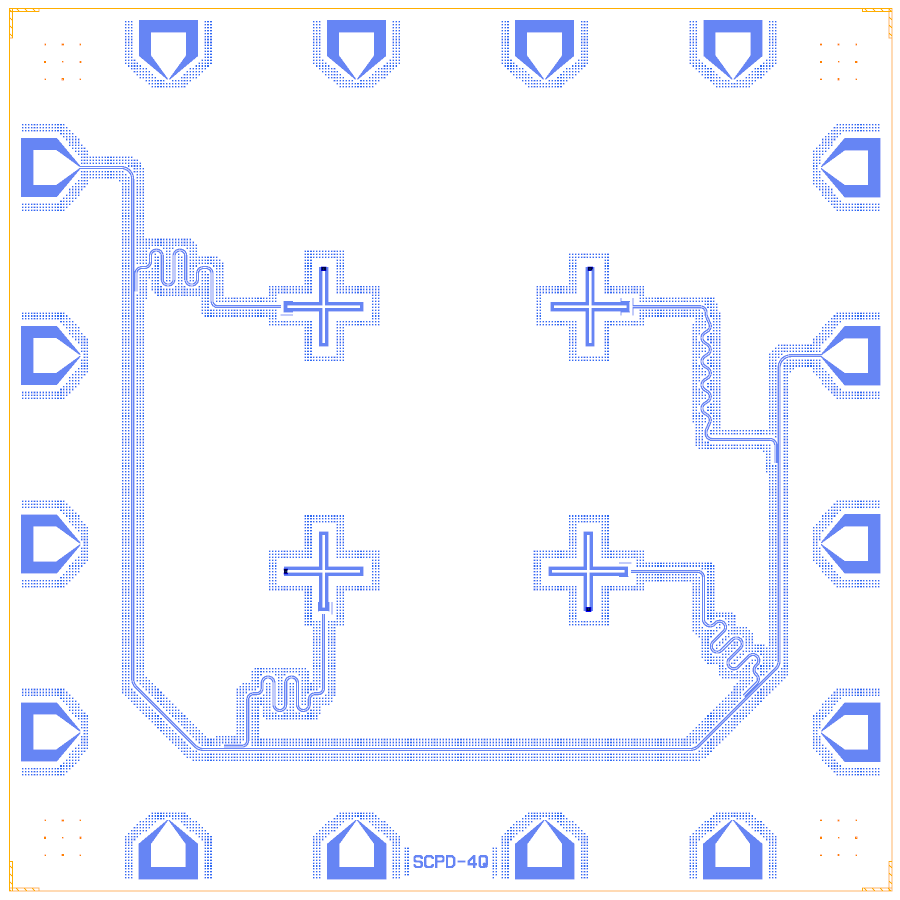

**On the chip so far:** 16 pads · 4 qubits · 0 other components · 5 routes · 0 declared couplings. **This step added** 4 route(s) `R1`, `R2`, `R3`, `R4`.

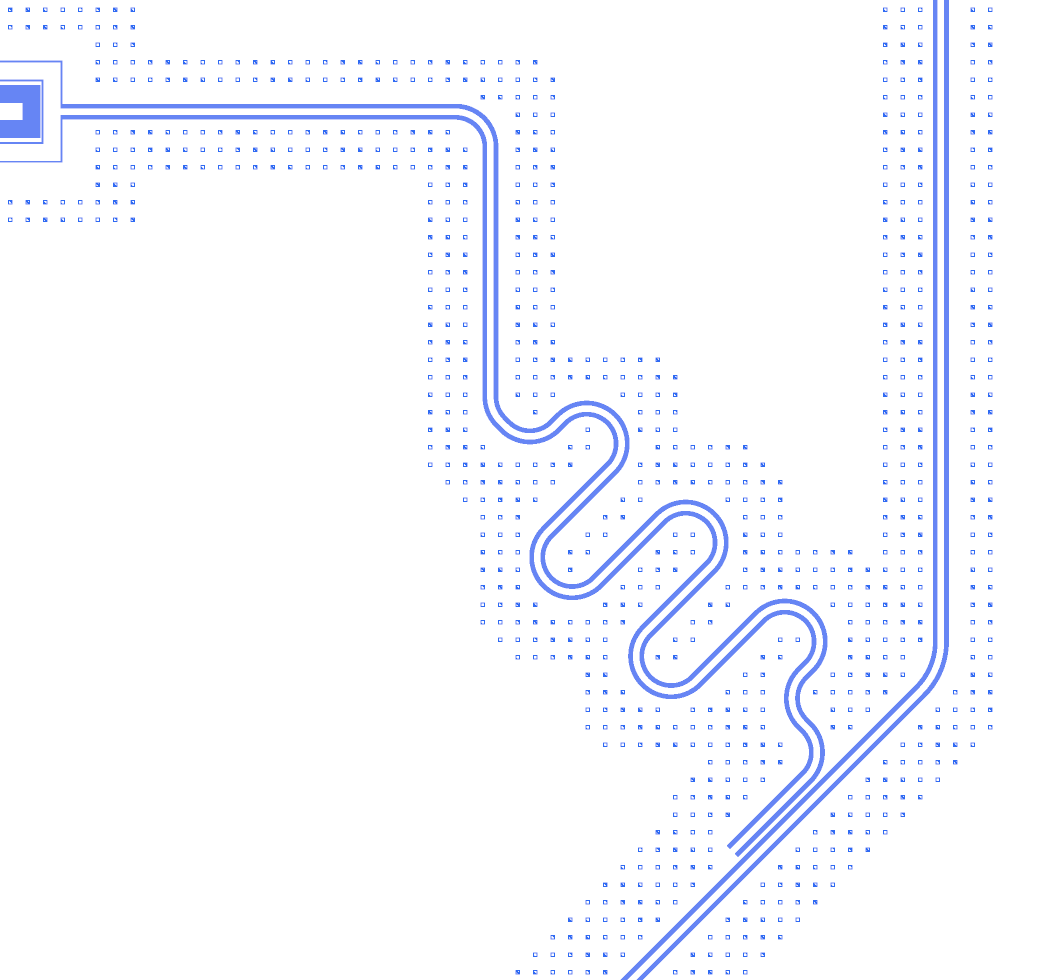

In [9]:
D_FIX, K_LEN = 2500.0, 200.0                     # config.toml: target_resonator_length; coupler footprint length
WIRE = {"R1": D_FIX - 75, "R2": D_FIX - 25, "R3": D_FIX + 25, "R4": D_FIX + 75}   # inside the ±100 µm tolerance
HANG = {"R1": ((1148.8, 3022.5), "forward"), "R2": ((6643.5, 1561.9), "backward"),    # source coupler centres
        "R3": ((6436.25, -465.65), "backward"), "R4": ((2026.5, -973.9), "backward")}
RNODES = {"R1": [(1822.7, 2790.1), (1822.7, 3122.5)], "R2": [(6022.8, 2789.2), (6022.8, 1661.9)],
          "R3": [(6000.0, 540.1), (6000.0, 112.02)], "R4": [(2772.2, -500.0), (2126.5, -500.0)]}
with d.batch():
    for k in range(1, 5):
        qk = q[f"Q{k}"]
        claw = next(p for p in qk.ports if p.startswith("claw"))
        (hx, hy), way = HANG[f"R{k}"]
        d.route(f"R{k}", qk[claw], fl.hanger(near=P(hx, hy), length=K_LEN, side="left", direction=way, end="short"),
                meander=WIRE[f"R{k}"] + K_LEN, r=50, nodes=PP(RNODES[f"R{k}"]))
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "scpd_4q_s5_readouts.png", size=(900, 900), width=320)
a, b = P(5300, -700), P(6800, 700)
snap(d, OUT / "scpd_4q_hanger.png", box=(*a, *b), size=(1050, 980), width=420);   # R3 on the 45° segment

## Design 6 · Coupling: four tunable couplers and the declared capacitances

**The couplers.** Each 814 × 1420 µm coupler block sits on an edge of the square, between two qubits. Its stand-in is
Qiskit Metal's `TunableCoupler01` (through `metal:`): a comb-shaped island with a SQUID to ground and a flux line. Its
island is set to `c_width` = 1400 µm, so the coupler's etch is as long as the block (1420 µm), and it lies on the line
between the two qubit centres with its fingers, SQUID and flux line on the outer side, where the block has its flux
port. `mirror=True` with the rotation puts the flux line on the same end of the coupler as the source's `port0`. The
SQUID is the PDK trilayer SQUID at L_J = 6.1 nH at zero flux (the low end of the window: parallel R_n ≈ 40 kΩ, the
highest coupler frequency). The cell's `Control` claw has no counterpart in the block and stays open
(`open_pins="Control"`). The block's `port1` / `port2` (the bridge pair) need no part: no wire crosses a coupler in
the routed benchmark.

**The couplings no route carries** are declared with `d.couple`, from coplanar-strip estimates (rough; the Q3D job
`core` of Simulate 2 replaces them):
- each qubit's arm tip faces the end of the coupler island, 115–122 µm apart, with a ground strip between the two
  etches (screening 0.5);
- the two qubits a coupler joins face each other across 1.64 mm with the coupler island on the line between them,
  which takes most of the field (screening 0.05). This direct capacitance sets where the coupling passes through zero
  (LOM 1 b), so the off point is as rough as this estimate.

coupler SQUID (zero flux): {'Lj_nH': 6.0129, 'Cj_fF': 16.8} → parallel R_n 40.2 kΩ


| coupling | C (fF) | note |
|---|---|---|
| `Cg_Q1_C12` | 1.38 | Q1 arm tip ↔ C12 island end, 122 µm (CPS estimate, ground strip between) |
| `Cg_Q2_C12` | 1.38 | Q2 arm tip ↔ C12 island end, 122 µm (CPS estimate, ground strip between) |
| `Cg_Q1_Q2` | 0.0607 | Q1 ↔ Q2 across C12, 1644 µm (CPS, screening 0.05) |
| `Cg_Q2_C23` | 1.402 | Q2 arm tip ↔ C23 island end, 115 µm (CPS estimate, ground strip between) |
| `Cg_Q3_C23` | 1.402 | Q3 arm tip ↔ C23 island end, 115 µm (CPS estimate, ground strip between) |
| `Cg_Q2_Q3` | 0.0609 | Q2 ↔ Q3 across C23, 1629 µm (CPS, screening 0.05) |
| `Cg_Q3_C34` | 1.401 | Q3 arm tip ↔ C34 island end, 115 µm (CPS estimate, ground strip between) |
| `Cg_Q4_C34` | 1.401 | Q4 arm tip ↔ C34 island end, 115 µm (CPS estimate, ground strip between) |
| `Cg_Q3_Q4` | 0.0609 | Q3 ↔ Q4 across C34, 1630 µm (CPS, screening 0.05) |
| `Cg_Q1_C14` | 1.401 | Q1 arm tip ↔ C14 island end, 115 µm (CPS estimate, ground strip between) |
| `Cg_Q4_C14` | 1.401 | Q4 arm tip ↔ C14 island end, 115 µm (CPS estimate, ground strip between) |
| `Cg_Q1_Q4` | 0.0609 | Q1 ↔ Q4 across C14, 1630 µm (CPS, screening 0.05) |

<metal:TunableCoupler01 C12 ports=['Control', 'Flux', 'squid_a', 'squid_b']>


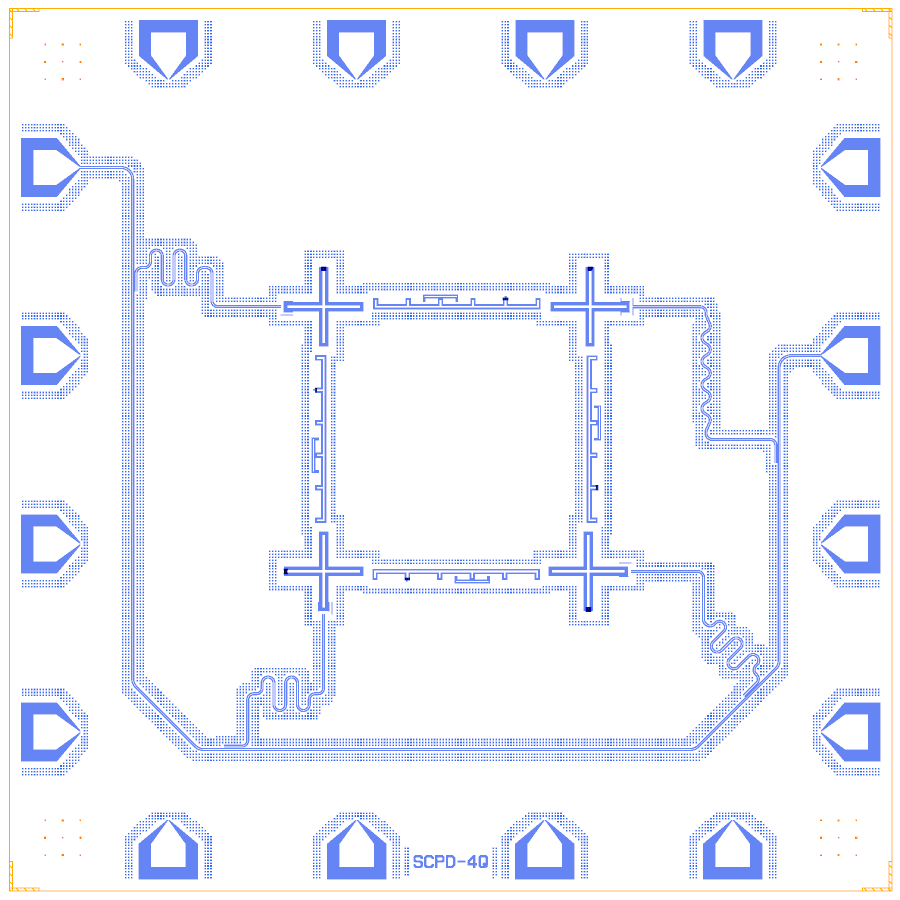

**On the chip so far:** 16 pads · 4 qubits · 4 other components · 5 routes · 12 declared couplings. **This step added** 4 component(s) `C12`, `C23`, `C34`, `C14`.

WindowsPath('examples/designs/community/scpd_4q_s6_couplers.png')

In [10]:
SQP, SQ = trilayer_junction("metal:TunableCoupler01", lj_nH=6.1, squid=True)
print("coupler SQUID (zero flux):", SQ, f"→ parallel R_n {rn_from_lj(SQ['Lj_nH']) / 1e3:.1f} kΩ")
TC = dict(c_width=1400, open_pins="Control")
COUPLERS = {"C12": ("Q1", "Q2", 180), "C23": ("Q2", "Q3", 90), "C34": ("Q3", "Q4", 0), "C14": ("Q1", "Q4", -90)}
CXY = {n: ((QXY[a][0] + QXY[b][0]) / 2, (QXY[a][1] + QXY[b][1]) / 2) for n, (a, b, _) in COUPLERS.items()}
c = {}
with d.batch():
    for n, (qa, qb, r) in COUPLERS.items():
        c[n] = d.add(n, "metal:TunableCoupler01", at=P(*CXY[n]), rot=r, mirror=True, junction=SQ, **TC, **SQP)
ARM = XMON["cross_length"] / 2                   # qubit centre → arm tip
for n, (qa, qb, _) in COUPLERS.items():
    for qn in (qa, qb):
        gap = math.dist(QXY[qn], CXY[n]) - ARM - TC["c_width"] / 2   # arm tip ↔ island end
        cg = round(est.coplanar_coupling(XMON["arm_width"], ARM, TC["c_width"] / 2, gap, EPS, screening=0.5), 3)
        d.couple(f"Cg_{qn}_{n}", qn, n, C_fF=cg,
                 note=f"{qn} arm tip ↔ {n} island end, {gap:.0f} µm (CPS estimate, ground strip between)")
    gap = math.dist(QXY[qa], QXY[qb]) - 2 * ARM   # arm tip ↔ arm tip across the coupler
    cqq = round(est.coplanar_coupling(XMON["arm_width"], ARM, ARM, gap, EPS, screening=0.05), 4)
    d.couple(f"Cg_{qa}_{qb}", qa, qb, C_fF=cqq, note=f"{qa} ↔ {qb} across {n}, {gap:.0f} µm (CPS, screening 0.05)")
display(Markdown("| coupling | C (fF) | note |\n|---|---|---|\n" + "\n".join(
    f"| `{k}` | {v['value']} | {v['note']} |" for k, v in d.data["couplings"].items())))
print(c["C12"])
layout_step(d, OUT / "scpd_4q_s6_couplers.png", size=(900, 900), width=320)

## Design 7 · Routing: drive and flux lines, five airbridges

**Drive ends.** Each source drive stub (182 × 330 µm, 80 µm off the qubit square, 50 µm off the arm axis) ends in a
`metal:OpenToGround` at the stub's inner end: an open CPW end facing the qubit's junction arm across the ground.

**Lines.** The eight wires follow the routed benchmark: the same launcher for each, the same 45° corners (read off the
routed GDS). The drive lines start at the open ends, the flux lines at the couplers' `Flux` pins; both are 10 / 6 µm
CPW (the `Flux` pin itself is 20 / 12 µm). Each flux pin sits about 500 µm inside its block (the coupler island is
smaller than the block), so the flux lines run on to it from the block edge. Where a wire crosses the feedline, a
waypoint with `airbridge=True` (`AB`) puts a KQC airbridge over it: five crossings, as in the benchmark.

{'XY1_line': 1641.0, 'XY2_line': 2466.4, 'XY3_line': 1862.4, 'XY4_line': 1759.3, 'Z12_line': 1975.6, 'Z23_line': 2073.9, 'Z34_line': 2199.5, 'Z14_line': 2096.4}


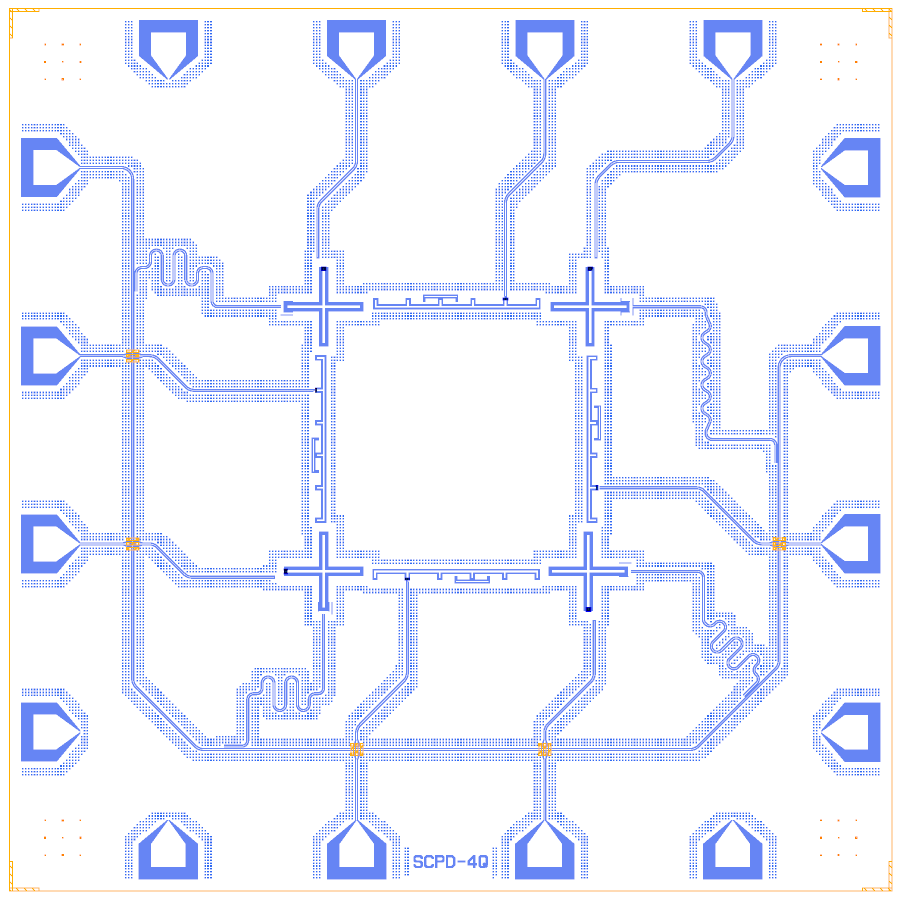

**On the chip so far:** 16 pads · 4 qubits · 8 other components · 13 routes · 12 declared couplings. **This step added** 4 component(s) `XY1`, `XY2`, `XY3`, `XY4` and 8 route(s) `XY1_line`, `XY2_line`, `XY3_line`, `XY4_line`, `Z12_line`, `Z23_line`, `Z34_line`, `Z14_line`.

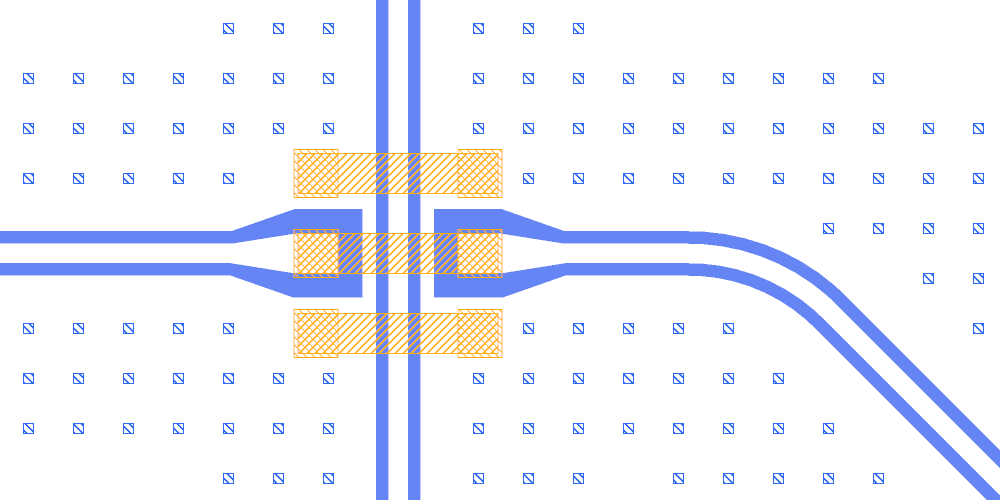

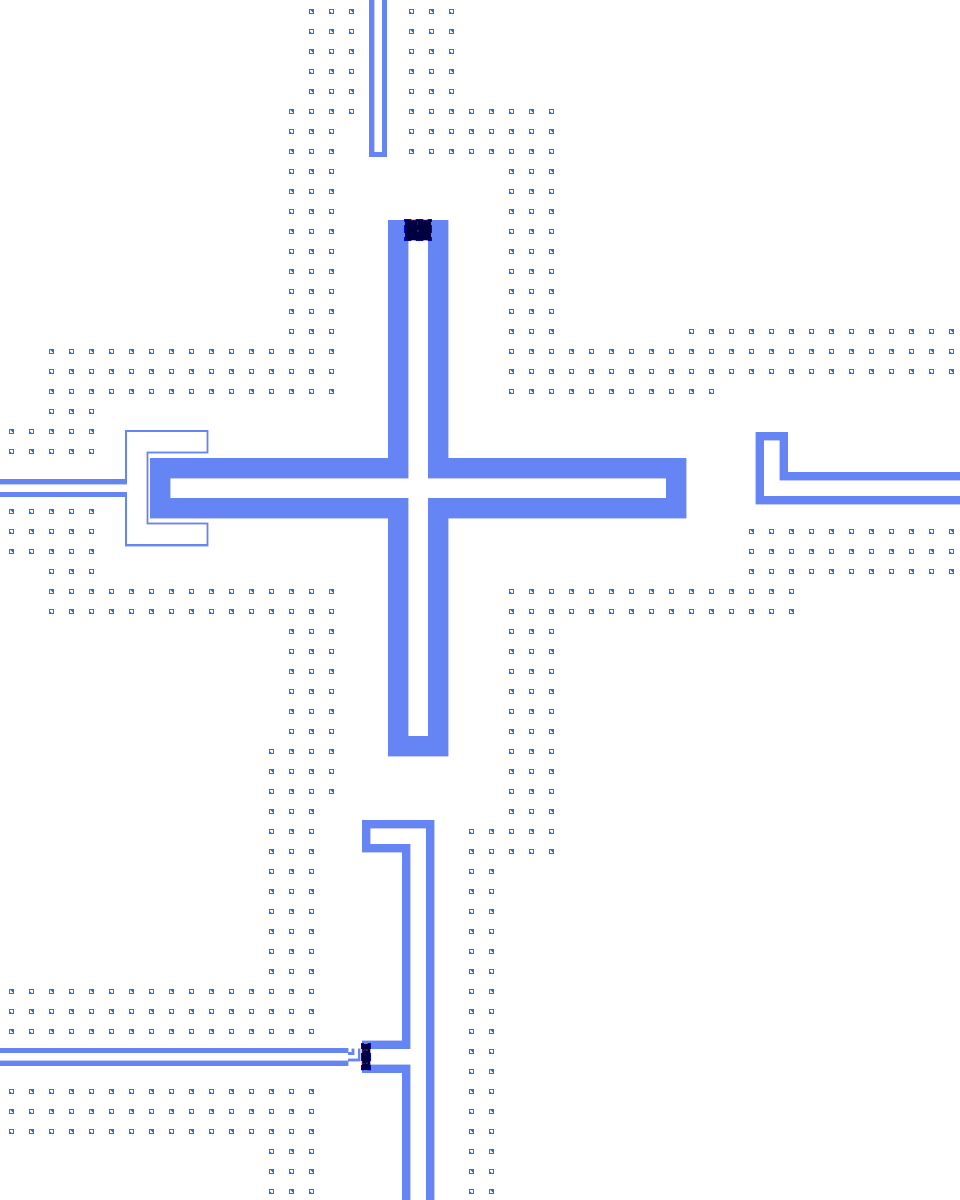

In [11]:
XY_ENDS = {"XY1": (2722.2, 3210.1, -90), "XY2": (5086.3, 3209.2, -90), "XY3": (5072.2, 120.1, 90),
           "XY4": (2352.2, 490.1, 0)}           # drive stubs' inner ends (source µm); the open gap faces the qubit
xy = {}
with d.batch():
    for n, (x, y, r) in XY_ENDS.items():
        xy[n] = d.add(n, "metal:OpenToGround", at=P(x, y), rot=r)
AB = lambda x, y: d.waypoint(P(x, y), airbridge=True)   # a KQC airbridge where the line crosses the feedline
CPW = dict(a=10, b=6)
with d.batch():
    d.route("XY1_line", xy["XY1"].open, L[14].a, nodes=PP([(2722.2, 3658.9), (3051.54, 3988.2)]), **CPW)
    d.route("XY2_line", xy["XY2"].open, L[12].a,
            nodes=PP([(5086.3, 3869.4), (5241.4, 4024.5), (6072.5, 4024.5), (6251.54, 4203.5)]), **CPW)
    d.route("XY3_line", xy["XY3"].open, L[6].a,
            nodes=PP([(5072.2, -367.8), (4651.54, -788.5)]) + [AB(4651.54, -973.9)], **CPW)
    d.route("XY4_line", xy["XY4"].open, L[2].a,
            nodes=PP([(1613.8, 490.2), (1330.7, 773.29)]) + [AB(1148.8, 773.29)], **CPW)
    d.route("Z12_line", c["C12"].Flux, L[13].a, nodes=PP([(4318.25, 3716.25), (4651.54, 4049.5)]), **CPW)
    d.route("Z23_line", c["C23"].Flux, L[9].a,
            nodes=PP([(5978.85, 1250.65), (6456.2, 773.29)]) + [AB(6643.6, 773.29)], **CPW)
    d.route("Z34_line", c["C34"].Flux, L[5].a,
            nodes=PP([(3483.2, -361.8), (3051.54, -793.5)]) + [AB(3051.54, -973.9)], **CPW)
    d.route("Z14_line", c["C14"].Flux, L[1].a,
            nodes=PP([(1629.9, 2079.1), (1335.7, 2373.29)]) + [AB(1148.8, 2373.29)], **CPW)
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.endswith("_line")})
layout_step(d, OUT / "scpd_4q_s7_control.png", size=(900, 900), width=320)
a, b = P(950, 2250), P(1450, 2500)
snap(d, OUT / "scpd_4q_bridge.png", box=(*a, *b), size=(1000, 500), width=420);   # Z14_line over the feedline
a, b = P(2250, 1900), P(3450, 3400)
snap(d, OUT / "scpd_4q_q1.png", box=(*a, *b), size=(960, 1200), width=380);   # Q1, its drive end, C12 and C14 ends

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups** say what a FEM job cuts out of the chip: one per qubit with its readout (`Q1_read` … `Q4_read`: Q3D
C-matrix and eigenmode, the box cuts the feedline beside the coupler) and the `core`, the four qubits, the four
couplers and the four drive ends (Q3D C-matrix: it replaces the declared couplings and gives the drive capacitances).
The source gives no frequencies, so the design carries no targets.

**Centring.** The launcher array is centred on the die (Design 1) and the pads sit symmetrically on all four edges, so
`center_in_die(d)` finds the content centred (a shift under its 50 µm tolerance is not applied) and moves nothing.
`DX, DY` follow the shift, so `P(x, y)` still maps source positions for the snapshots.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): a run that changes nothing says *same design*.

shift applied (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/community/scpd_4q.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer scpd_4q: 28 instances, 13 routes, live=False> → examples\designs\community\scpd_4q.json
control wires: 16.07 mm (the benchmark: 10.32 mm between block ports); feedline 13.74 mm


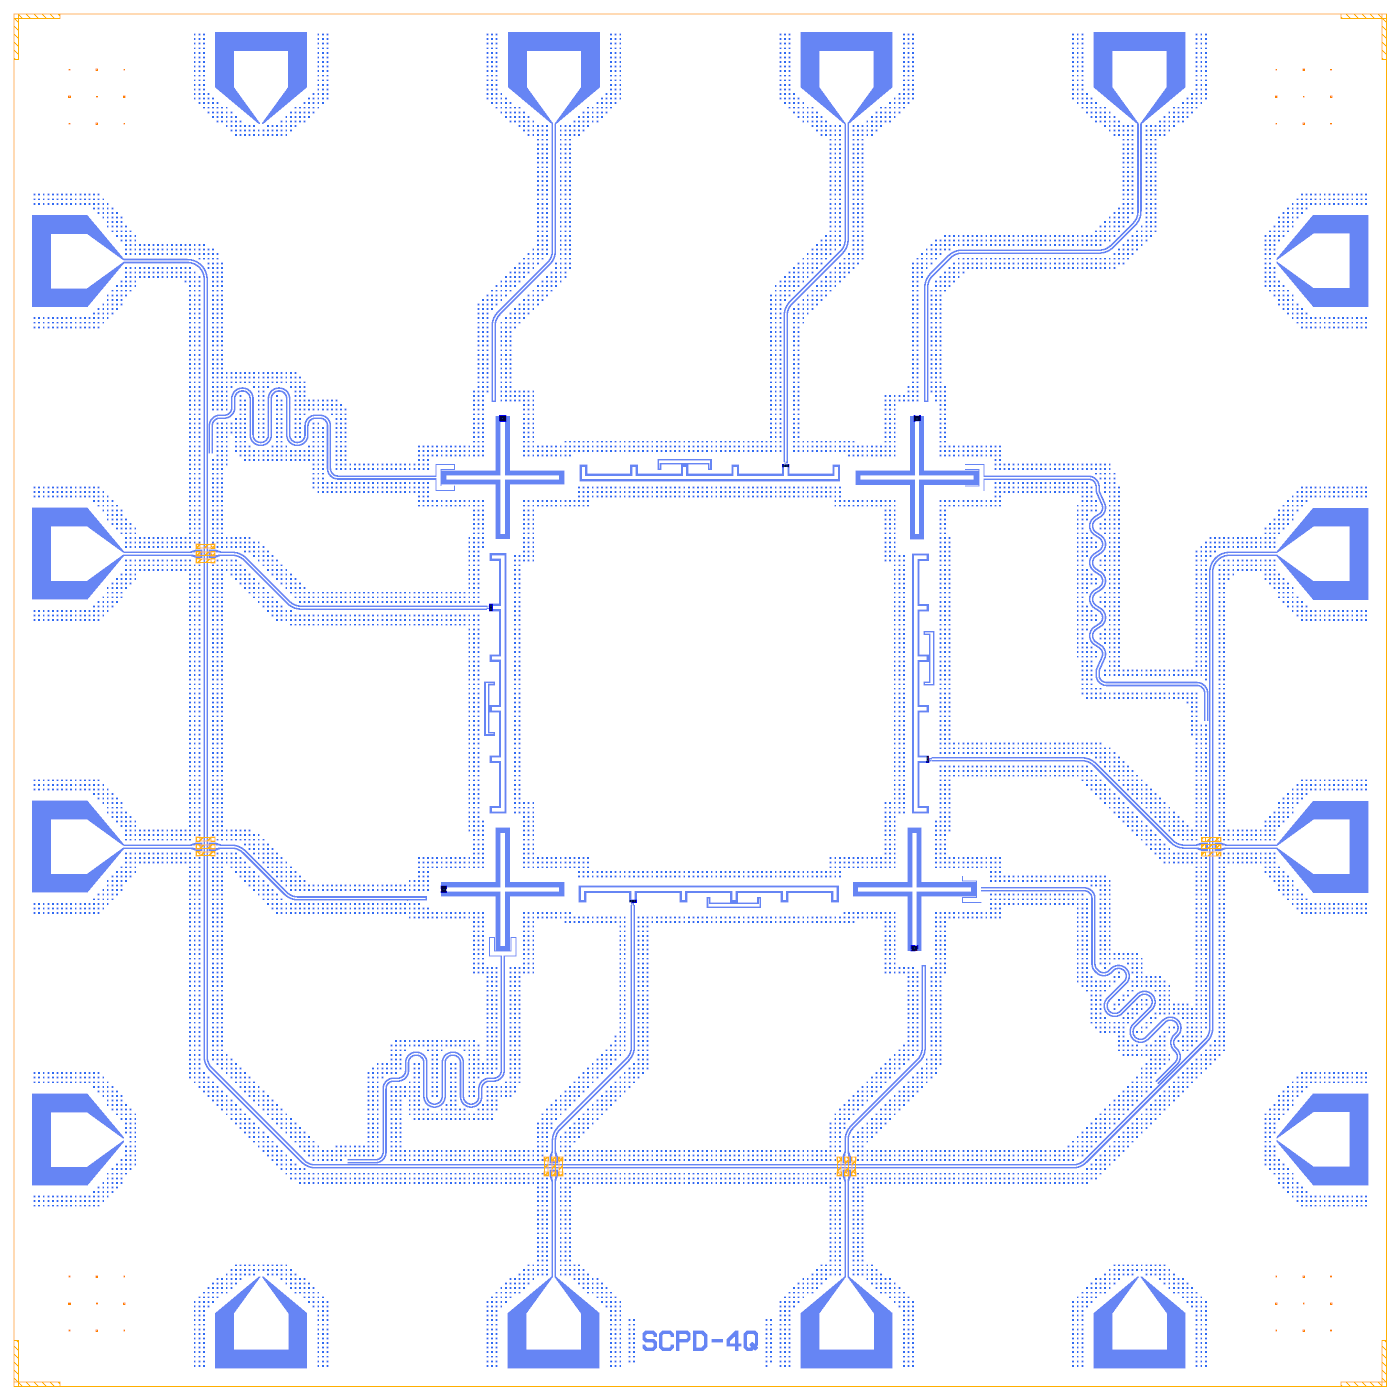

**On the chip so far:** 16 pads · 4 qubits · 8 other components · 13 routes · 12 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/scpd_4q_routes.png')

In [12]:
READ = [f"Q{k}_read" for k in range(1, 5)]
for k in range(1, 5):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"R{k}"], margin_um=60, analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("core", [*QXY, *COUPLERS, *XY_ENDS], margin_um=60, analyses=["q3d_cmatrix"])
shift = center_in_die(d)
DX, DY = DX + shift[0], DY + shift[1]            # keep P(x, y) = source → Designer after the shift
print("shift applied (µm):", shift)
rebuild(d)
DESIGN, same = save_design(d, OUT / "scpd_4q.json")
display(Markdown(same))
print(d, "→", DESIGN)
lengths = d.result.route_lengths()
wires = sum(v for k, v in lengths.items() if k.endswith("_line"))
print(f"control wires: {wires / 1e3:.2f} mm (the benchmark: 10.32 mm between block ports); feedline "
      f"{lengths['FL'] / 1e3:.2f} mm")
layout_step(d, OUT / "scpd_4q_routes.png", size=(1400, 1400), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK margins:
- **errors** would make the chip wrong; there must be none (the five crossings carry airbridges);
- **warnings** are worth a look but can be intended: here the couplers' open `Control` claws and their SQUID
  attachment points (`squid_a` / `squid_b`, drawn by the cell), and the six launchers the benchmark leaves unused;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced. None are expected: every launcher is at 100 µm, the junctions are inside the R_n window
  and the design has no frequency targets.

From the layout run on 2026-11-19: **0 errors, 18 `dangling_port` warnings** (4 `Control`, 8 SQUID points, 6
launchers), **0 PDK design warnings**. `pdk_report(d)` sums up the PDK checks.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` maps every component's ports to circuit nodes:
- each `Xmon` is a grounded island with its junction and a claw node;
- each claw → hanger route is a λ/4 `TLres` with a hanger κ into the feedline `FL` (one conductor between the two
  50 Ω launchers `L0` and `L10`);
- each `TunableCoupler01` is a grounded island with its SQUID, the open `Control` claw as a node and the flux line as
  a control; its flux line's launcher drops out (the flux T-line shorts to ground);
- the drive ends are 50 Ω drive ports ending open; the unused launchers are 50 Ω ports on their own;
- the twelve `d.couple` capacitances join each coupler to its two qubits and the two qubits to each other.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

**(a) Qubit + readout pairs**, each with the feedline (QuCat normal modes, then the QuTiP dressed values). The four
qubits are identical (the same cross and junction) and come out together; the readouts step down with their lengths.
From the run on 2026-11-19:
- every qubit at **4.866 GHz** (α −137 MHz) with the PDK nominal junction, inside the PDK band of 4–8 GHz;
- the readouts at **10.03 / 9.87 / 9.72 / 9.57 GHz**: the benchmark's 2.5 mm λ/4 is short for a readout on sapphire,
  so they sit 4.7–5.2 GHz above the qubits, and χ is small (−0.056 … −0.059 MHz) with κ 0.21–0.23 MHz through the
  200 µm hangers. Flagged, not retuned: the length is the benchmark's.

In [ ]:
read = {f"Q{k}+R{k}": [f"Q{k}", f"R{k}", "FL"] for k in range(1, 5)}
res = simulate_groups(d, read)
display(Markdown(groups_md(res)))

**(b) Coupler sweep: g̃ and ZZ against the coupler frequency** (Q1–C12–Q2; the other three edges are the same). The
coupler's SQUID L_J is stepped from its drawn zero-flux value (6.0 nH, the coupler's maximum frequency) upwards:
L_J(Φ) = L_J0/|cos πΦ|, so each row is a flux bias Φ. With the two identical qubits degenerate, the dressed
splitting of their levels is 2|g̃|; the sign is that of Yan et al., PR Applied 10, 054062 (2018), Eq. 5 on the same
LOM capacitances (listed too). For ZZ, Q2 is detuned by its L_J (`DETUNE_LJ`) and the static ZZ of the detuned pair is
read from the dressed levels.

From the run on 2026-11-19: the coupler sits at 6.04 GHz at zero flux, 1.2 GHz above the qubits. The arm-tip
couplings are small (1.4 fF across 115–122 µm), so g̃ stays small: +0.47 MHz at zero flux, zero at f_c ≈ 5.50 GHz
(L_J,c 7.20 nH, Φ ≈ 0.19 Φ0), where the coupler-mediated part cancels the direct one (the 0.06 fF estimate of
Design 6), and −2.2 MHz at 5.05 GHz. Yan's Eq. 5 follows the LOM splitting within 0.1 MHz. The detuned pair's static
ZZ goes from +15 kHz at zero flux through zero near the off point to −36 kHz at 5.05 GHz.

In [ ]:
LJ_C = [6.0, 6.25, 6.5, 6.75, 7.0, 7.25, 7.5, 7.75, 8.0, 8.25, 8.5]
DETUNE_LJ = 7.0                                  # Q2 L_J for the ZZ column (≈ 0.1 GHz below Q1)
sweep = coupler_sweep(d, ["Q1", "C12", "Q2"], "Q1", "Q2", "C12", LJ_C, detune_lj=DETUNE_LJ)
display(Markdown(coupler_sweep_md(sweep)))
display(Markdown(f"ZZ column: Q2 at {sweep[0]['f_q2_detuned_GHz']:.3f} GHz (L_J {DETUNE_LJ} nH), "
                 f"Q1 at {sweep[0]['f_q1_GHz']:.3f} GHz."))
off = off_point(sweep)
display(Markdown(f"**Off point:** g̃ = 0 at f_c ≈ {off['f_c_GHz']:.3f} GHz (L_J,c ≈ {off['lj_nH']:.2f} nH, "
                 f"Φ ≈ {off['flux_phi0']:.3f} Φ0)" if off else "**Off point:** not inside the sweep"))
plot_coupler_sweep(sweep, OUT / "scpd_4q_sweep.png", title="scpd_4q: Q1–C12–Q2 coupler sweep (LOM)")

## LOM 2 · The LOM in two plots

The pair results as pictures: (a) every normal mode of each qubit's group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout. The plot
shows the four qubits on one frequency and the four readouts stepped 150–160 MHz apart, about 5 GHz above them.

`plot_lom` draws (b) on a log axis. The four |χ| lie within 7 % of each other, and matplotlib then labels every
minor tick of that axis so the labels run into each other; for this one call the cell gives the log axis a few plain
tick labels instead.

In [ ]:
import matplotlib.axes
import matplotlib.ticker as mticker

_set_xscale = matplotlib.axes.Axes.set_xscale


def _few_log_labels(ax, value, **kw):            # a log axis over a narrow range: four plain labels, no minor ones
    _set_xscale(ax, value, **kw)
    if value == "log":
        ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
        ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.4f"))
        ax.xaxis.set_minor_formatter(mticker.NullFormatter())


matplotlib.axes.Axes.set_xscale = _few_log_labels
try:
    plot_lom(res, OUT / "scpd_4q_lom.png", title="scpd_4q: LOM per qubit + readout")
finally:
    matplotlib.axes.Axes.set_xscale = _set_xscale

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The LOM is cheap, so a design change can be checked in seconds. The four
qubits share one frequency, which a fixed-frequency lattice avoids. Here Q1's cross is shortened from 620 to 560 µm
tip to tip in a copy: a smaller island capacitance raises f_q and |α|. (The arm tip then sits 30 µm further from
both couplers, so the declared couplings would shrink as well; the copy keeps them.) `design_copy` opens a second,
non-live Designer on the saved design, so the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q1"].set(cross_length=560)                   # 620 → 560 µm tip to tip
res2 = simulate_groups(d2, {"Q1+R1": read["Q1+R1"]})
display(Markdown(params_delta_md({"Q1+R1": res["Q1+R1"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/community/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Five sim groups, nine jobs: a Q3D C-matrix job for each qubit with its readout and for the `core` (the four qubits,
the four couplers and the drive ends), and an eigenmode/EPR job for each qubit with its readout (lines leaving the box
end in 50 Ω). The jobs are self-contained folders `build/jobs/<design>_<group>_<analysis>`. Exporting again replaces
a folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at
the top) picks the fast test settings for every job exported from here on. With `RUN_FEM = True` the next cells solve
each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an AEDT window you have open is never
touched. Elsewhere: `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/community/fem/: solved results are kept here
jobs = export_sims(DESIGN, READ + ["core"], analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, READ, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

Each qubit's group gives the cross island, its claw and the readout line the box cuts as named nets (`Q1.island`,
`Q1.claw_e`, …); the `core` gives the qubit islands, the coupler islands (`C12.island`, …) and the drive ends, so its
matrix replaces the twelve `d.couple` estimates. Each net is named after its LOM node, so the matrix goes straight
into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that
there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The four qubit groups in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet and the feedline ends the box cuts
end in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`)
turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes), the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q1_read`: R1 is a hanger on the feedline, so S21 between
the two feedline ends the box cuts shows its notch (f_r and the external κ); the other three groups are the same with
other readout lengths.

In [ ]:
f_r0 = res["Q1+R1"].params.get("R1.f_GHz")      # the LOM's readout frequency (LOM 1 a)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1_read", jobs_eig["Q1_read"][0], keep_eig["Q1_read"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1_read"]:
    display(Markdown(driven_md(keep_drv["Q1_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {f"Q{k}_read": (f"Q{k}", f"R{k}", f"Q{k}+R{k}") for k in range(1, 5)}   # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = res[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "scpd_4q_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q1_read"]:
    qb, rr, _ = PAIRS["Q1_read"]
    fem_values.setdefault("Q1_read", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q1_read"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR, and the S21 notch of R1.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

Below the table: Q1–C12–Q2 on the `core` C-matrix, with the coupler at its drawn zero-flux L_J, once that job is
kept: the normal modes with the measured qubit–coupler and qubit–qubit capacitances in place of the estimates (LOM 1 b
can then be rerun on them).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = res[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=read[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

if keep_q3d.get("core"):
    core_fem = simulate(fill(d.lom(select=["Q1", "C12", "Q2"]).model, DESIGN, keep_q3d["core"]), max_modes=3)
    display(Markdown("**Q1–C12–Q2 on the `core` C-matrix (coupler at zero flux), QuCat normal modes:**\n\n"
                     + modes_md(core_fem)))

## Results 4 · Feedback: one step towards a target

The source states no frequencies, so the design file carries no targets. This notebook's exercise target is the
usual one for fixed-frequency qubits on tunable couplers: neighbours detuned from each other, here a checkerboard
of **Q1 and Q3 at 4.80 GHz, Q2 and Q4 at 4.95 GHz** (LOM 1: all four at 4.866 GHz). The readouts keep their lengths
(no f_r target). `target_copy(DESIGN, TARGETS)` writes the design with these targets to `build/scpd_4q_target.json`,
and the feedback works on that copy.

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit (the couplers have no readout: they are not pairs), on the Q3D values where a solve was kept, and picks one
value per quantity (the consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put
the targets inside their tolerance (f_q ± 20 MHz): here each qubit's L_J. `pdk_lj_bounds` keeps every junction inside
the 40–50 kΩ window. The proposal is written as revision 1, built and netlist-checked. From a run on 2026-11-19: the
consensus puts all four qubits at 4.821 GHz (SQcircuit), the proposal moves L_J from 6.73 to 6.79 nH (Q1, Q3) and to
6.40 nH (Q2, Q4), both inside the window, and revision 1 is on target (Results 5 stops after one step).

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 4.80}, "Q2": {"f_q_GHz": 4.95}, "Q3": {"f_q_GHz": 4.80}, "Q4": {"f_q_GHz": 4.95}}
DESIGN_T = target_copy(DESIGN, TARGETS)          # the exercise targets, on a copy
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision, check whether it is on target, else feed back again for the next
revision, until every target is inside its tolerance or `MAX_ITER` revisions are made (`build/scpd_4q/revisions/`).
Without `RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` the Q3D jobs of the four qubit groups are
exported and solved first for each revision (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT
minutes). The table shows each iteration's values against the targets and the knobs it moved; the plot the residual in
tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    # RUN_FEM: revision k's four qubit Q3D jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in READ}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "scpd_4q_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/community/scpd_4q.json` (Design 8): cells, positions,
  routes, couplings and sim groups; `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: the benchmark has no cheese of its own). The table lists each fab layer (13 970 holes
  and the five airbridges' 15 bridges in a run on 2026-11-19).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps the five
  airbridges in a FEM export (none of the sim groups here contains one); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/scpd_4q.json`, `qcc design drc …`,
  `qcc mask …` (the fab file), `qcc sim build … -g Q1_read -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
FAB = Path("build") / "scpd_4q_fab.oas"
display(Markdown(fab_layers_md(d, path=FAB, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full die (PDK frame, device ID `SCPD-4Q`); qubit Q1 with its claw, the open drive end above its junction arm and
the island ends of C12 and C14; Q1's trilayer junction; the C12 coupler with its SQUID and flux line; and the fab mask
round Q1 (the PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0 and 3/0).

In [ ]:
snap(d, OUT / "scpd_4q.png", size=(1600, 1600))
qx, qy = P(*QXY["Q1"])
cx, cy = P(*CXY["C12"])
snap(d, OUT / "scpd_4q_q1_fab.png", box=(qx - 500, qy - 600, qx + 600, qy + 500), size=(1100, 1100), width=420)
snap(d, OUT / "scpd_4q_jj.png", box=(qx - 40, qy + 290, qx + 40, qy + 370), width=300)
snap(d, OUT / "scpd_4q_c12.png", box=(cx - 740, cy - 60, cx + 740, cy + 160), size=(1480, 220), width=640)
snap_file(FAB, OUT / "scpd_4q_cheese.png", box=(qx - 500, qy - 600, qx + 600, qy + 500), size=(1100, 1100), width=420);

## Summary

- **Matches the source:** every block of the 4Q benchmark as a library component at the block's position and
  orientation; the routed benchmark's connections (one feedline over four hangers, four drive and four flux wires to
  the same launchers, five airbridges at the same crossings) on its corner points; the resonator wire inside the
  benchmark's 2500 ± 100 µm.
- **Changed by the PDK:** the 7.5 mm die with its frame; launchers 100 µm from the edges (200–400 µm further out than
  the source's); sapphire; trilayer junctions and SQUIDs; the PDK cheese band.
- **Open PDK design warnings:** none.
- **Known limits:** the source has no device geometry, so the qubit cross, the coupler island and the coupling gaps
  are this rebuild's choices inside the blocks; the qubit–coupler and direct couplings are rough estimates until the
  `core` Q3D job has run, and with them the coupler's off point (LOM 1 b); the 2.5 mm λ/4 puts the readouts near
  10 GHz (χ ≈ −0.06 MHz).
- **Feedback:** towards an exercise target on a copy (the source has none): `loop.analyse`, `loop.feedback`, revisions
  until on target (LOM; FEM with `RUN_FEM`), PDK L_J bounds.
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with
  `RUN_FEM = True` to fill the Simulate and Results cells.